In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels

In [2]:
statsmodels.__version__

'0.15.0'

In [3]:
# load the data
df = pd.read_csv('./Time-Series-Analysis-Resources/5-AutoRegressive/data/us_airline_carrier_passenger.csv')
df.head()

,month,passengers
0,2000-01-01,46492
1,2000-02-01,48526
2,2000-03-01,58764
3,2000-04-01,56033
4,2000-05-01,58201


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   month       240 non-null    str  
 1   passengers  240 non-null    int64
dtypes: int64(1), str(1)
memory usage: 6.2 KB


In [5]:
df['month'] = pd.to_datetime(df['month'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   month       240 non-null    datetime64[us]
 1   passengers  240 non-null    int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 3.9 KB


<Axes: xlabel='month', ylabel='passengers'>

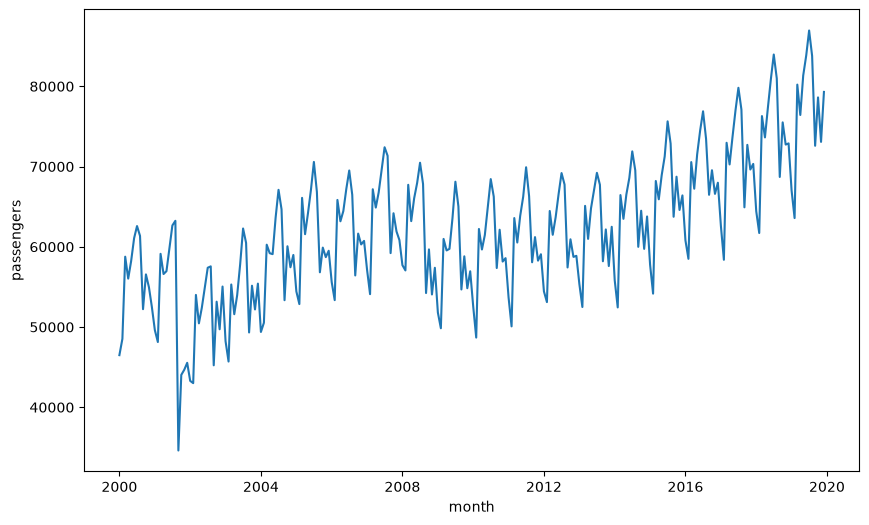

In [7]:
# visualize the data
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x='month', y='passengers')

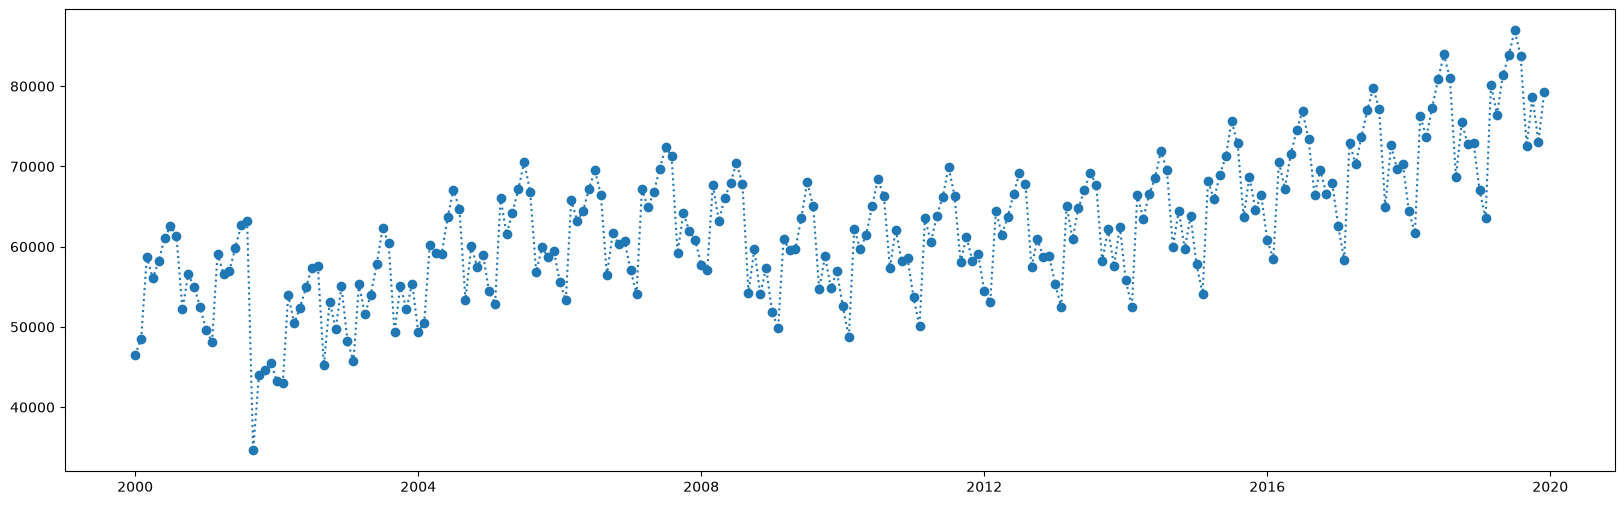

In [9]:
# visualize the data
plt.figure(figsize=(20, 6))
#sns.lineplot(data=df, x='month', y='passengers')
plt.plot(df['month'], df['passengers'],'o:')

**Splitting the data into train and test**
- train : upto 2016-dec
- test : 2016-dec to 2019-dec

In [14]:
df_train = df[df['month'] <= '2016-12-01']
df_test = df[df['month'] > '2016-12-01']

In [15]:
df_train.tail()

,month,passengers
199,2016-08-01,73450
200,2016-09-01,66477
201,2016-10-01,69539
202,2016-11-01,66591
203,2016-12-01,67983


In [16]:
df_test.head()

,month,passengers
204,2017-01-01,62621
205,2017-02-01,58377
206,2017-03-01,72962
207,2017-04-01,70262
208,2017-05-01,73679


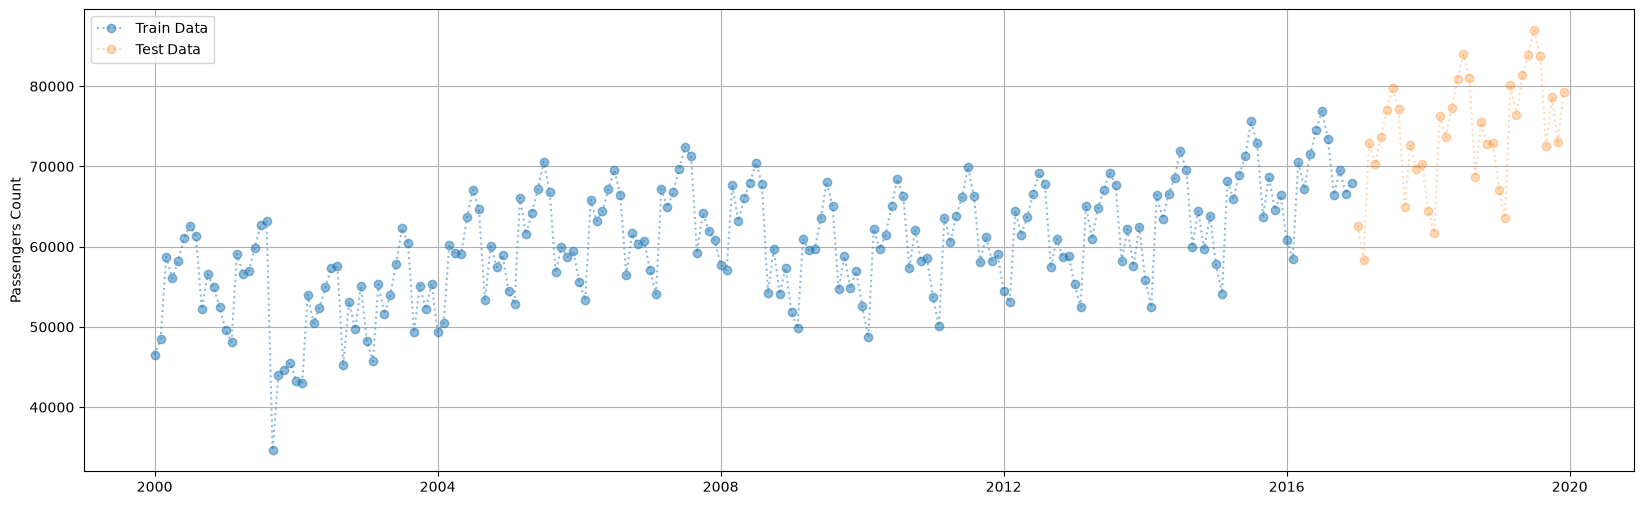

In [ ]:
plt.figure(figsize=(20, 6))
plt.plot(df_train['month'], df_train['passengers'],'o:',alpha=0.5)
plt.plot(df_test['month'], df_test['passengers'],'o:',alpha=0.3)
plt.legend(['Train Data','Test Data'])
plt.ylabel('Passengers Count')
plt.grid(True)
plt.show()

### ACF and PACF plots

In [21]:
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf

Text(0.5, 0, 'Lags')

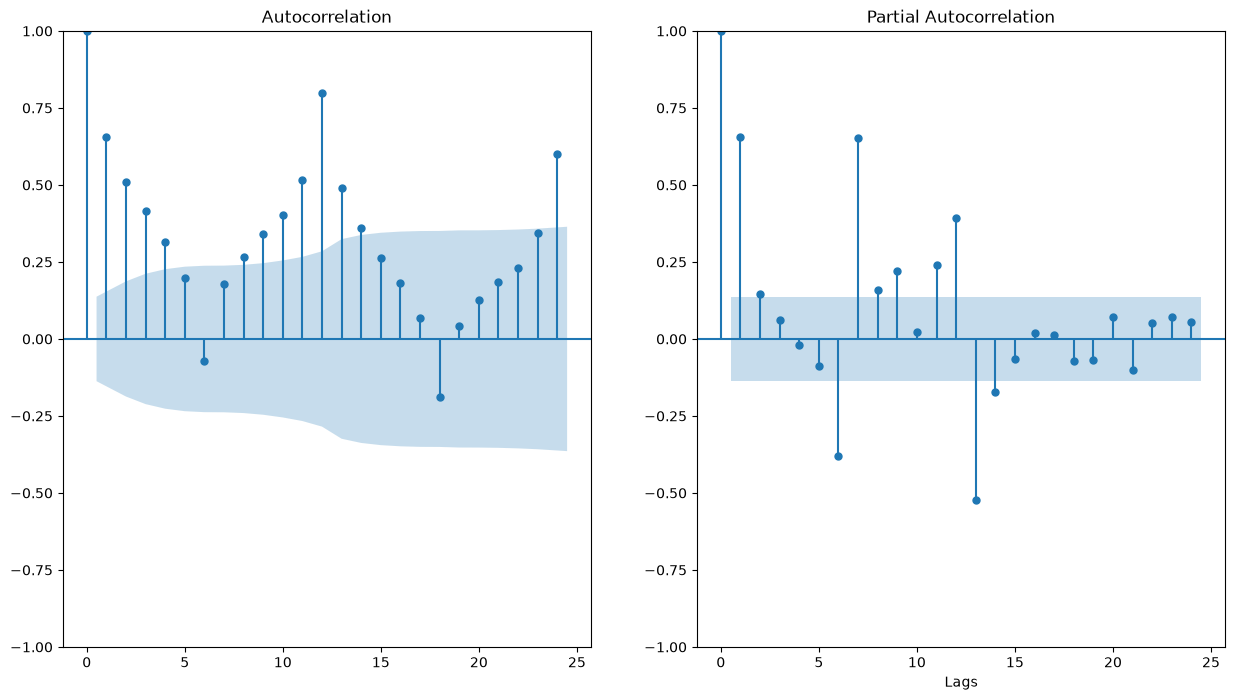

In [24]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(15,8))
res1 = plot_acf(df_train['passengers'],ax=ax[0])
plt.xlabel('Lags')
res2 = plot_pacf(df_train['passengers'],ax=ax[1])
plt.xlabel('Lags')

**Making Data Stationary**

In [26]:
difference = df_train['passengers'].diff()
difference

0          NaN
1       2034.0
2      10238.0
3      -2731.0
4       2168.0
        ...   
199    -3436.0
200    -6973.0
201     3062.0
202    -2948.0
203     1392.0
Name: passengers, Length: 204, dtype: float64

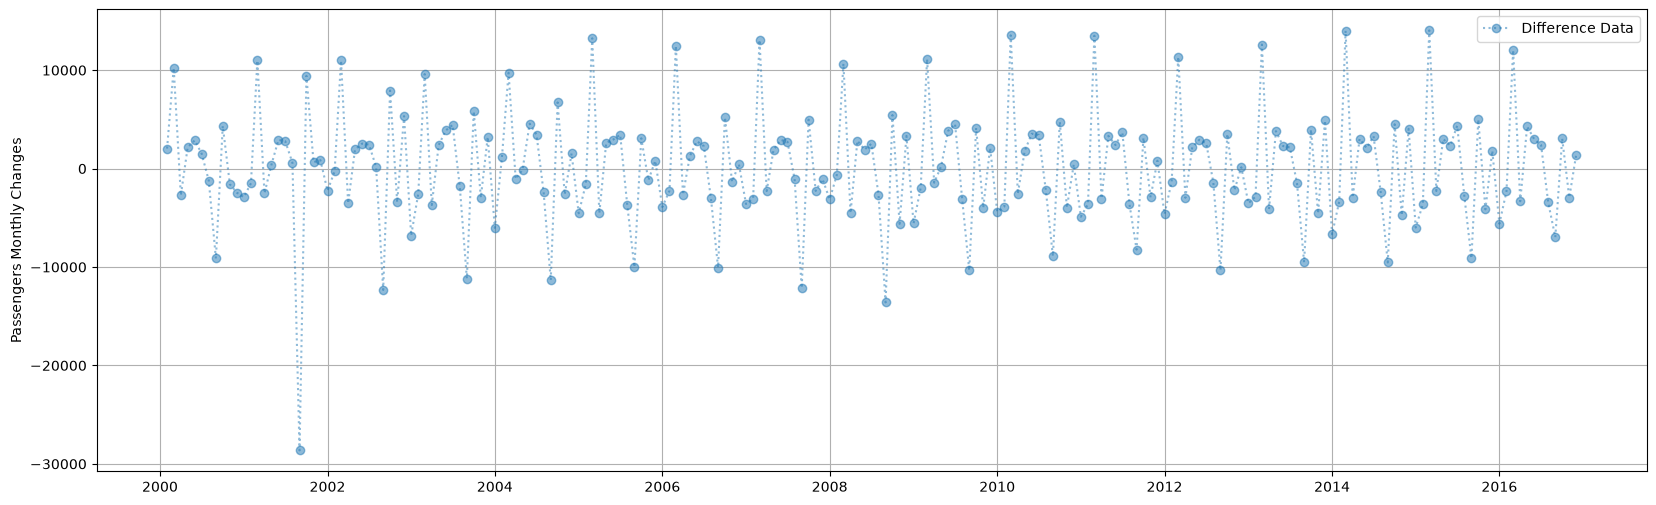

In [27]:
plt.figure(figsize=(20, 6))
plt.plot(df_train['month'], difference,'o:',alpha=0.5)
plt.legend(['Difference Data'])
plt.ylabel('Passengers Monthly Changes')
plt.grid(True)
plt.show()

In [28]:
difference.dropna(inplace=True) # drop the missing values before computing acf and pacf otherwise you will get error

Text(0.5, 0, 'Lags')

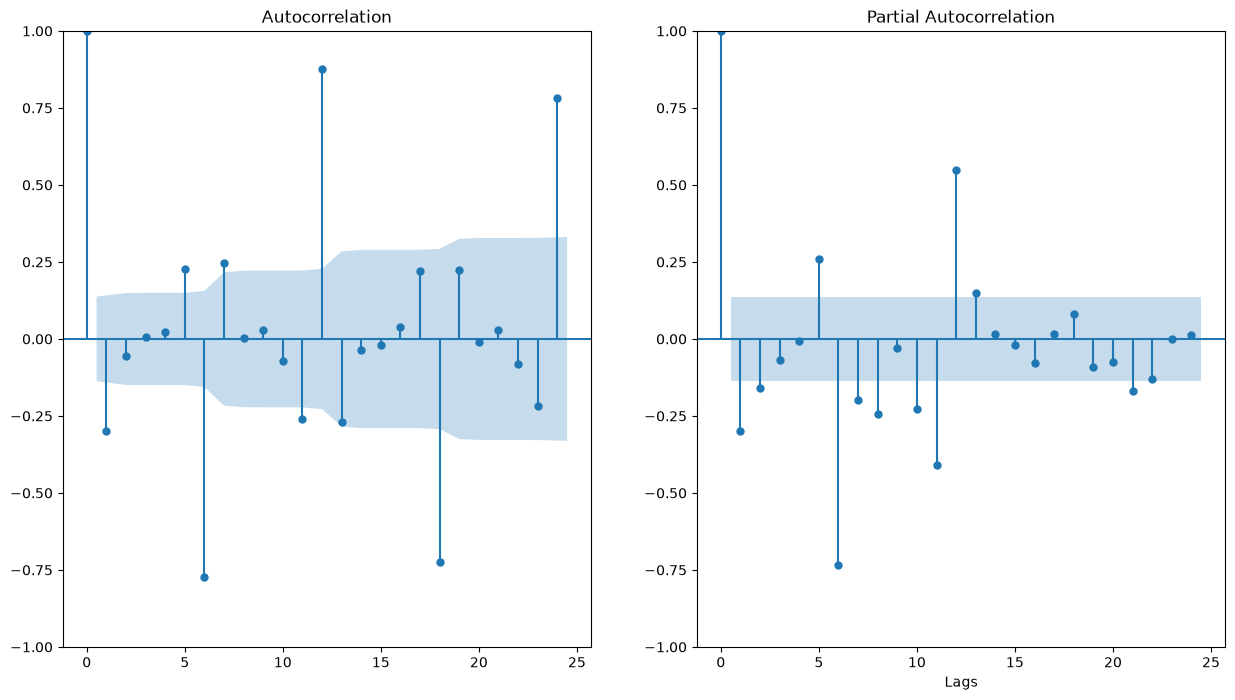

In [29]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(15,8))
res1 = plot_acf(difference,ax=ax[0])
plt.xlabel('Lags')
res2 = plot_pacf(difference,ax=ax[1])
plt.xlabel('Lags')

Clear seasonality at 12 periods

**Auto-Regressive Model**
- AR(p)
- p = number of lags
- find p using PACF (find the number of lags which are not zero)
- 12 lags from PACF
- AR(12) model

In [30]:
df_train.set_index('month')

,passengers
month,
2000-01-01,46492
2000-02-01,48526
2000-03-01,58764
2000-04-01,56033
2000-05-01,58201
...,...
2016-08-01,73450
2016-09-01,66477
2016-10-01,69539


In [31]:
x_train = df_train.set_index('month')
x_test = df_test.set_index('month')

In [32]:
from statsmodels.tsa.ar_model import AutoReg


In [33]:
model_ar = AutoReg(x_train, lags=12)
model_ar = model_ar.fit()

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [34]:
print(model_ar.summary())

                            AutoReg Model Results                             
Dep. Variable:             passengers   No. Observations:                  192
Model:                    AutoReg(12)   Log Likelihood               -1791.208
Method:               Conditional MLE   S.D. of innovations           2725.128
Date:                Wed, 25 Nov 2026   AIC                           3610.416
Time:                        00:02:42   BIC                           3656.021
Sample:                    01-01-2001   HQIC                          3628.887
                         - 12-01-2016                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const          -1101.8877   2670.461     -0.413      0.680   -6335.894    4132.119
passengers.L1      0.4234      0.062      6.848      0.000       0.302       0.545
passengers.L2      0.0487      0.069

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/statsmodels/tsa/ar_model.py:482: RuntimeWarning: divide by zero encountered in matmul
  return self._y.squeeze() - (self._x @ params).squeeze()
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/statsmodels/tsa/ar_model.py:482: RuntimeWarning: overflow encountered in matmul
  return self._y.squeeze() - (self._x @ params).squeeze()
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/statsmodels/tsa/ar_model.py:482: RuntimeWarning: invalid value encountered in matmul
  return self._y.squeeze() - (self._x @ params).squeeze()
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/statsmodels/tsa/ar_model.py:738: RuntimeWarning: divide by zero encountered in matmul
  in_sample = x @ params
/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/statsmodels/tsa/ar_

In [35]:
# fitted values
fittedvalues = model_ar.fittedvalues

In [36]:
fittedvalues.head()

month
2001-01-01    49334.710929
2001-02-01    49964.903006
2001-03-01    57480.606603
2001-04-01    55642.948449
2001-05-01    57963.182409
dtype: float64

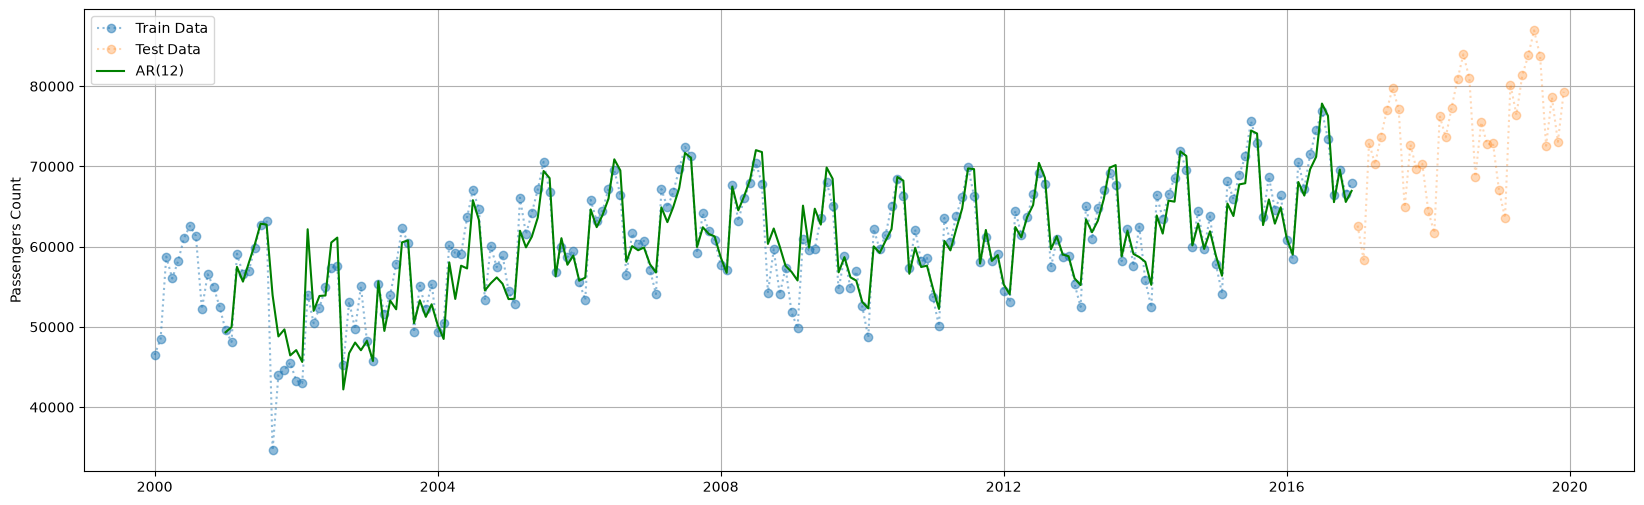

In [38]:
plt.figure(figsize=(20, 6))
plt.plot(df_train['month'], df_train['passengers'],'o:',alpha=0.5)
plt.plot(df_test['month'], df_test['passengers'],'o:',alpha=0.3)

# fitted values
plt.plot(fittedvalues,'g-',label='Fitted Values')

plt.legend(['Train Data','Test Data','AR(12)'])
plt.ylabel('Passengers Count')
plt.grid(True)
plt.show()

In [39]:
import datetime

In [41]:
start = datetime.datetime.strptime('2017-01-01','%Y-%m-%d')
end = datetime.datetime.strptime('2019-12-01','%Y-%m-%d')
forecast_values = model_ar.predict(start=start,end=end)
forecast_values.head(3)


/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/statsmodels/tsa/deterministic.py:305: UserWarning: Only PeriodIndexes, DatetimeIndexes with a frequency set, RangesIndexes, and Index with a unit increment support extending. The index is set will contain the position relative to the data length.
  fcast_index = self._extend_index(index, steps, forecast_index)


2017-01-01    63865.557371
2017-02-01    63222.994100
2017-03-01    70781.913370
Freq: MS, dtype: float64

In [43]:
ME = 1.96*model_ar.resid.std()
ME

np.float64(5355.214235866174)

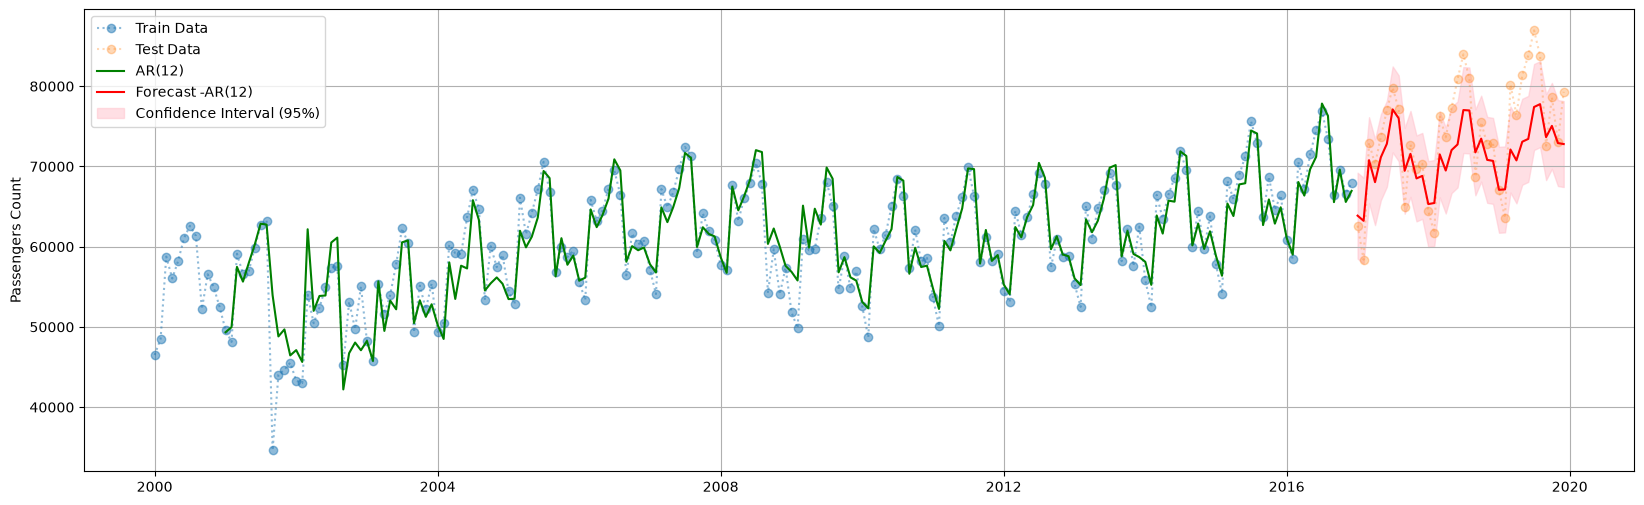

In [44]:
plt.figure(figsize=(20, 6))
plt.plot(df_train['month'], df_train['passengers'],'o:',alpha=0.5)
plt.plot(df_test['month'], df_test['passengers'],'o:',alpha=0.3)

# fitted values
plt.plot(fittedvalues,'g-',label='Fitted Values')

# forecasted values
plt.plot(forecast_values,'r-',label='Forecasted Values')

# confidence interval
plt.fill_between(df_test['month'], (forecast_values.values-ME),(forecast_values.values+ME), color='pink', alpha=0.5)

plt.legend(['Train Data','Test Data','AR(12)','Forecast -AR(12)', 'Confidence Interval (95%)'])
plt.ylabel('Passengers Count')
plt.grid(True)
plt.show()

**Evaluation**

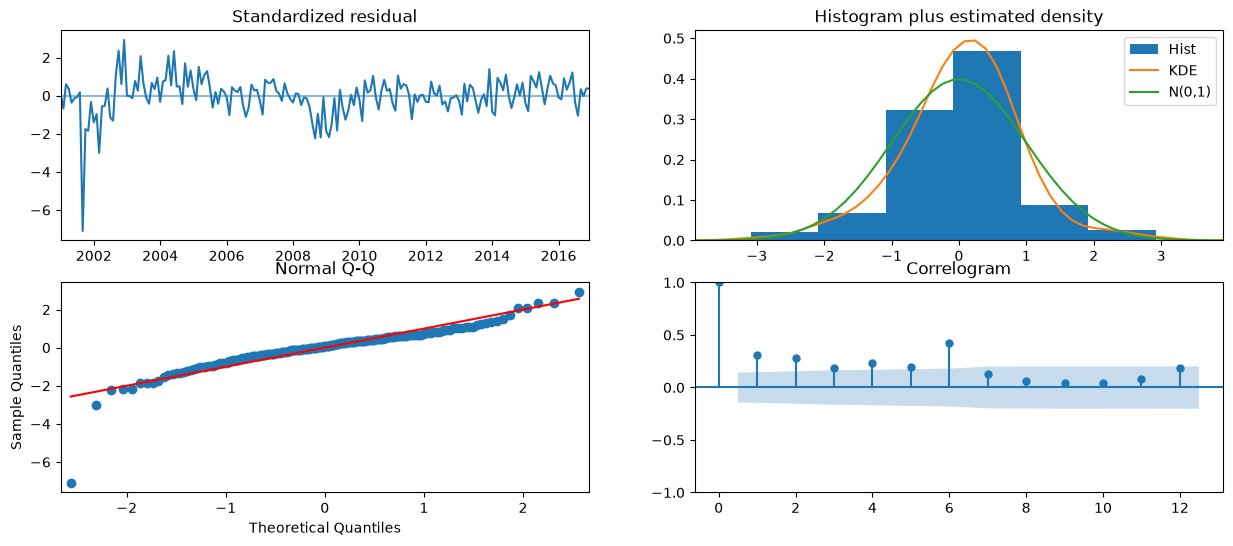

In [46]:
fig = plt.figure(figsize=(15,6))
fig = model_ar.plot_diagnostics(lags=12,fig=fig)